# 1. Báo cáo Nghiên cứu: Mô hình Hồi quy Đa thức Dự đoán Điểm GPA Học kỳ Sau (Post-Semester GPA)
## 1.1 Thiết kế Schema Đặc trưng 12 Biến Gốc (Nhóm A - D) & Khung Phân tích Đánh giá Kịch bản Dự đoán

---

### 1.1.1 Nguyên tắc thiết kế đặc trưng và phòng chống rò rỉ thông tin (Anti-Leakage Protocol)
Trong bài toán ứng dụng thực tế, người dùng chỉ nhập **12 đặc trưng thô (raw features)** thuộc 4 nhóm chức năng A–D. Toàn bộ các bước mã hóa (encoding), chuẩn hóa (scaling), mở rộng đa thức (polynomial expansion) và chọn lọc biến đều được đóng gói tự động trong Pipeline:

1. **Nhóm A – Đặc trưng Học thuật Ban đầu (Academic Features)**:
   - `Pre_Semester_GPA`: Biến liên tục, hệ số tương quan Pearson $r = 0,9264$ (biến dự báo mạnh nhất).
   - `Traditional_Study_Hours`: Biến liên tục, đo lường thời gian tự học truyền thống.
   - `Year_of_Study`: Mã hóa One-Hot (mặc dù có thứ bậc nhưng không giả định khoảng cách giữa các năm học là cách đều).
   - `Major_Category`: Mã hóa One-Hot (kiểm soát độ lệch điểm giữa các nhóm ngành).

2. **Nhóm B – Hành vi và Năng lực Khai thác GenAI (AI Usage Features)**:
   - `Weekly_GenAI_Hours`: Biến số liên tục trọng tâm (mở rộng phi tuyến để nắm bắt quy luật bão hòa).
   - `Tool_Diversity`: Biến số liên tục đếm số lượng công cụ.
   - `Primary_Use_Case`: Mã hóa One-Hot.
   - `Prompt_Engineering_Skill`: Mã hóa One-Hot.
   - `Paid_Subscription`: Biến nhị phân {0, 1}.

3. **Nhóm C – Bối cảnh Chính sách Thể chế (Contextual Features)**:
   - `Institutional_Policy`: Mã hóa One-Hot (kiểm tra tác động của quy định quản lý AI).

4. **Nhóm D – Trạng thái Tâm lý & Hành vi (Psychological Features)**:
   - `Perceived_AI_Dependency`: Mã hóa One-Hot.
   - `Anxiety_Level_During_Exams`: Mã hóa One-Hot.

> **Quy tắc loại trừ nghiêm ngặt (Strict Exclusion)**:
> Tuyệt đối **không** đưa vào ma trận $X$ các biến: `Student_ID`, `GPA_Change`, `Skill_Retention_Score`, hoặc `Burnout_Risk_Level`. Lý do: `Skill_Retention_Score` và `Burnout_Risk_Level` có nguy cơ rò rỉ thông tin theo thời gian (thường chỉ đo lường vào cuối kỳ hoặc đồng thời sau khi đã có kết quả).

### 1.1.2 Hai kịch bản mô hình thực nghiệm
- **Phiên bản 1 (Mô hình Trước kỳ học - Prospective Pre-Semester Model)**: Sử dụng các Nhóm **A + B + C** (10 biến gốc). Dành cho kịch bản tư vấn đầu kỳ khi chưa có thông tin tâm lý phòng thi.
- **Phiên bản 2 (Mô hình Giả định Kịch bản - Conditional What-If Analysis Model)**: Sử dụng toàn bộ các Nhóm **A + B + C + D** (12 biến gốc).


In [1]:
import os
import sys
import json
import hashlib
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import joblib

from sklearn.preprocessing import StandardScaler, OneHotEncoder, PolynomialFeatures
from sklearn.linear_model import LinearRegression, Ridge, Lasso
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score
from sklearn.model_selection import KFold

# Publication-grade visualization styles (Academic Standards)
plt.style.use('seaborn-v0_8-whitegrid')
plt.rcParams['font.family'] = 'DejaVu Sans'
plt.rcParams['figure.figsize'] = (10, 6)
plt.rcParams['axes.titlesize'] = 12
plt.rcParams['axes.labelsize'] = 11
plt.rcParams['xtick.labelsize'] = 10
plt.rcParams['ytick.labelsize'] = 10

# Discover repository root dynamically
ROOT = next((p for p in [Path.cwd(), *Path.cwd().parents]
             if (p / 'pyproject.toml').is_file() and (p / 'data/train/dataset.csv').is_file()), None)
if ROOT is None:
    raise FileNotFoundError("[ERROR] Khong tim thay thu muc goc repository Lab 01.")

sys.path.insert(0, str(ROOT / 'src'))
from lab01_ml.models.factory import create_polynomial_pipeline
from lab01_ml.visualization.plots import (
    plot_gpa_distribution, plot_ai_hours_distribution,
    plot_ai_hours_vs_gpa_change, plot_group_heatmap,
    plot_residuals
)

DATA_DIR = ROOT / 'data'
OUTPUT_DIR = ROOT / 'outputs/polynomial'
FIG_DIR = OUTPUT_DIR / 'figures'
TABLE_DIR = OUTPUT_DIR / 'tables'
MODEL_DIR = OUTPUT_DIR / 'models'

for d in [FIG_DIR, TABLE_DIR, MODEL_DIR]:
    d.mkdir(parents=True, exist_ok=True)

print(f"[INFO] Da thiet lap moi truong tinh toan thanh cong. Repository Root: {ROOT}")


[INFO] Da thiet lap moi truong tinh toan thanh cong. Repository Root: /home/faze01/Homespace/linear_regression/ML-24KHMT2-Lab01


---
# 2. Thu thập Dữ liệu & Xác thực Toàn vẹn Dữ liệu (Data Provenance & Schema)
## 2.1 Kiểm tra mã băm SHA-256 đối soát metadata.json và loại trừ rò rỉ dữ liệu


In [2]:
metadata_path = DATA_DIR / 'metadata.json'
assignment_path = DATA_DIR / 'assignments.csv'

metadata = json.loads(metadata_path.read_text(encoding='utf-8'))
if hashlib.sha256(assignment_path.read_bytes()).hexdigest() != metadata['assignment_sha256']:
    raise ValueError("[ERROR] Ma bam assignments.csv khong khop voi metadata.json!")

for split in ['train', 'validation']:
    split_path = DATA_DIR / split / 'dataset.csv'
    split_hash = hashlib.sha256(split_path.read_bytes()).hexdigest()
    if split_hash != metadata['dataset_sha256'][f'{split}/dataset.csv']:
        raise ValueError(f"[ERROR] Ma bam {split}/dataset.csv khong khop metadata.json!")

train_df = pd.read_csv(DATA_DIR / 'train/dataset.csv')
val_df = pd.read_csv(DATA_DIR / 'validation/dataset.csv')

print("[INFO] Kiem tra toan ven du lieu thanh cong theo SHA-256 metadata.json.")
print(f"[DATA INFO] Kich thuoc tap Train:      {train_df.shape}")
print(f"[DATA INFO] Kich thuoc tap Validation: {val_df.shape}")

# Dinh nghia danh sach cac bien theo Schema quy dinh
num_cols = ['Pre_Semester_GPA', 'Traditional_Study_Hours', 'Weekly_GenAI_Hours', 'Tool_Diversity']
cat_cols_abc = ['Year_of_Study', 'Major_Category', 'Primary_Use_Case', 'Prompt_Engineering_Skill', 'Institutional_Policy']
cat_cols_d = ['Perceived_AI_Dependency', 'Anxiety_Level_During_Exams']
bin_cols = ['Paid_Subscription']
target_col = 'Post_Semester_GPA'

# Kiem tra loai bo cac bien nguy co ro ri
excluded_cols = ['Student_ID', 'Skill_Retention_Score', 'Burnout_Risk_Level', 'GPA_Change']
for col in excluded_cols:
    if col in num_cols or col in cat_cols_abc or col in cat_cols_d or col in bin_cols:
        raise ValueError(f"[VIOLATION] Phat hien bien ro ri trong danh sach input: {col}")
print(f"[VERIFICATION] Da xac nhan loai bo hoan toan cac bien ro ri: {excluded_cols}")


[INFO] Kiem tra toan ven du lieu thanh cong theo SHA-256 metadata.json.
[DATA INFO] Kich thuoc tap Train:      (35000, 16)
[DATA INFO] Kich thuoc tap Validation: (7500, 16)
[VERIFICATION] Da xac nhan loai bo hoan toan cac bien ro ri: ['Student_ID', 'Skill_Retention_Score', 'Burnout_Risk_Level', 'GPA_Change']


---
# 3. Phân tích Khám phá Dữ liệu Huấn luyện (Exploratory Data Analysis)
## 3.1 Khảo sát phân phối và mối liên hệ phi tuyến ban đầu trên tập Train


[INFO] Sinh bo bieu do kham pha phan phoi tap Train...


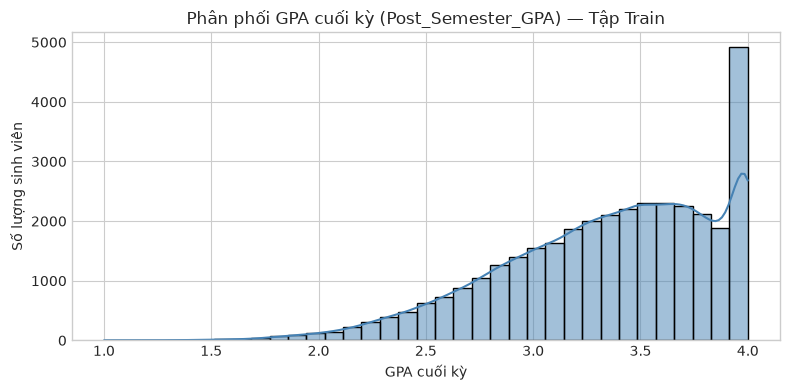

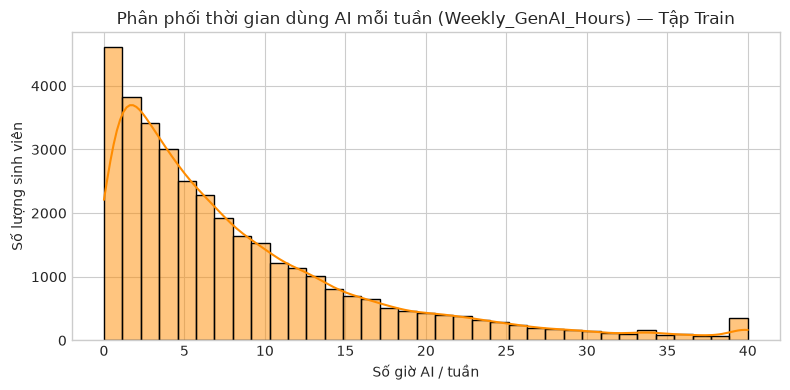

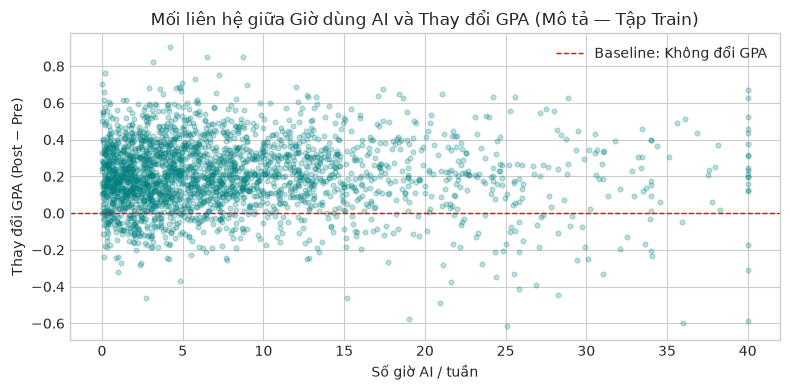

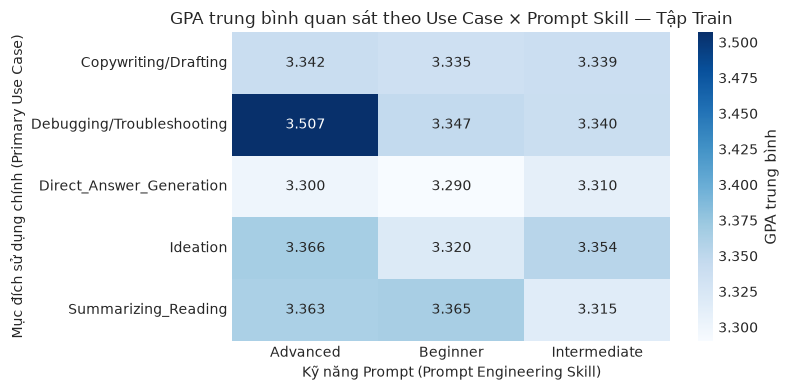

[INFO] Da luu 4 bieu do kham pha vao: /home/faze01/Homespace/linear_regression/ML-24KHMT2-Lab01/outputs/polynomial/figures


In [3]:
print("[INFO] Sinh bo bieu do kham pha phan phoi tap Train...")

fig1, ax1 = plot_gpa_distribution(train_df, save_path=FIG_DIR / '01_gpa_distribution.png')
plt.show()

fig2, ax2 = plot_ai_hours_distribution(train_df, save_path=FIG_DIR / '02_ai_hours.png')
plt.show()

fig3, ax3 = plot_ai_hours_vs_gpa_change(train_df, save_path=FIG_DIR / '03_ai_gpa_change.png')
plt.show()

fig4, ax4 = plot_group_heatmap(train_df, save_path=FIG_DIR / '04_group_heatmap.png')
plt.show()

print(f"[INFO] Da luu 4 bieu do kham pha vao: {FIG_DIR}")


---
# 4. Pipeline Tiền xử lý & Mở rộng Đa thức Tinh gọn
## 4.1 Cấu trúc tiền xử lý và mở rộng đa thức trên các biến số liên tục

Mở rộng đa thức được thực hiện tập trung trên **4 biến số liên tục**:
$$\mathbf{x}_{num} = [\text{Pre\_GPA}, \text{Study\_Hours}, \text{GenAI\_Hours}, \text{Tool\_Diversity}]$$
- Các biến phân loại (Year, Major, Policy, Anxiety,...) được mã hóa One-Hot (drop='first') và giữ nguyên dạng tuyến tính.
- Biến nhị phân (`Paid_Subscription`) được giữ nguyên dưới dạng {0, 1}.


In [4]:
def transform_pipeline(train_data, val_data, use_group_d=False, degree=1):
    cat_cols = cat_cols_abc + (cat_cols_d if use_group_d else [])

    # 1. One-Hot Encoding cho bien phan loai
    ohe = OneHotEncoder(drop='first', sparse_output=False, handle_unknown='ignore')
    tr_cat = ohe.fit_transform(train_data[cat_cols])
    va_cat = ohe.transform(val_data[cat_cols])

    # 2. Bien nhi phan
    tr_bin = train_data[bin_cols].astype(int).values
    va_bin = val_data[bin_cols].astype(int).values

    # 3. Chuan hoa bien so lien tuc
    num_scaler = StandardScaler()
    tr_num = num_scaler.fit_transform(train_data[num_cols])
    va_num = num_scaler.transform(val_data[num_cols])

    # 4. Mo rong da thuc tren bien lien tuc
    if degree > 1:
        poly = PolynomialFeatures(degree=degree, include_bias=False)
        tr_poly = poly.fit_transform(tr_num)
        va_poly = poly.transform(va_num)

        poly_scaler = StandardScaler()
        tr_poly_s = poly_scaler.fit_transform(tr_poly)
        va_poly_s = poly_scaler.transform(va_poly)
    else:
        tr_poly_s, va_poly_s = tr_num, va_num

    X_tr = np.hstack([tr_poly_s, tr_cat, tr_bin])
    X_va = np.hstack([va_poly_s, va_cat, va_bin])

    y_tr = train_data[target_col].values
    y_va = val_data[target_col].values

    return X_tr, X_va, y_tr, y_va, X_tr.shape[1]

print("[INFO] Da thiet lap thanh cong pipeline tien xu ly.")


[INFO] Da thiet lap thanh cong pipeline tien xu ly.


---
# 5. Thực nghiệm So sánh Đa thức (Degrees 1 - 6) & 5-Fold Cross Validation
## 5.1 Đánh giá Đa thức kết hợp điều chuẩn Ridge và Lasso

Quét bậc đa thức từ $d = 1$ đến $d = 6$ với:
- **5-Fold Cross Validation trên tập Train**: Đo lường trung bình và độ lệch chuẩn của RMSE.
- **Đối chiếu trên tập Validation**: Đo lường $	ext{MSE}_{val}$ và $R^2_{val}$.


In [5]:
degrees = [1, 2, 3, 4, 5, 6]
alphas_ridge = [1e-3, 1e-2, 0.1, 1.0, 10.0, 50.0, 100.0]
alphas_lasso = [1e-4, 5e-4, 1e-3, 5e-3, 1e-2]

kf = KFold(n_splits=5, shuffle=True, random_state=42)

results_all = []
trained_models_storage = {}

for version_name, use_d in [('Version 1 (No Group D)', False), ('Version 2 (With Group D)', True)]:
    print("=" * 72)
    print(f"[STEP] Bat dau thuc nghiem: {version_name}")
    print("=" * 72)

    for deg in degrees:
        X_tr, X_va, y_tr, y_va, n_feats = transform_pipeline(
            train_df, val_df, use_group_d=use_d, degree=deg
        )

        # 5-fold CV folds tren train cho Ridge mac dinh
        cv_rmses = []
        for tr_idx, hld_idx in kf.split(X_tr):
            r_fold = Ridge(alpha=50.0, random_state=42)
            r_fold.fit(X_tr[tr_idx], y_tr[tr_idx])
            pred_fold = r_fold.predict(X_tr[hld_idx])
            cv_rmses.append(np.sqrt(mean_squared_error(y_tr[hld_idx], pred_fold)))
        cv_rmse_mean = float(np.mean(cv_rmses))
        cv_rmse_std = float(np.std(cv_rmses))

        # 1. OLS Baseline
        ols = LinearRegression()
        ols.fit(X_tr, y_tr)
        va_pred_ols = ols.predict(X_va)
        mse_tr_ols = mean_squared_error(y_tr, ols.predict(X_tr))
        mse_va_ols = mean_squared_error(y_va, va_pred_ols)
        r2_va_ols = r2_score(y_va, va_pred_ols)
        results_all.append({
            'version': version_name, 'degree': deg, 'model': 'OLS', 'alpha': None, 'features': n_feats,
            'train_mse': mse_tr_ols, 'val_mse': mse_va_ols, 'val_rmse': np.sqrt(mse_va_ols), 'val_r2': r2_va_ols,
            'cv_rmse_mean': cv_rmse_mean, 'cv_rmse_std': cv_rmse_std
        })
        trained_models_storage[(version_name, deg, 'OLS')] = ols

        # 2. Ridge Tuning
        best_ridge_mse = float('inf')
        best_ridge_model, best_ridge_alpha = None, None
        for a in alphas_ridge:
            r = Ridge(alpha=a, random_state=42)
            r.fit(X_tr, y_tr)
            mse_v = mean_squared_error(y_va, r.predict(X_va))
            if mse_v < best_ridge_mse:
                best_ridge_mse = mse_v
                best_ridge_alpha = a
                best_ridge_model = r

        r2_ridge = r2_score(y_va, best_ridge_model.predict(X_va))
        tr_mse_ridge = mean_squared_error(y_tr, best_ridge_model.predict(X_tr))
        results_all.append({
            'version': version_name, 'degree': deg, 'model': 'Ridge', 'alpha': best_ridge_alpha, 'features': n_feats,
            'train_mse': tr_mse_ridge, 'val_mse': best_ridge_mse, 'val_rmse': np.sqrt(best_ridge_mse), 'val_r2': r2_ridge,
            'cv_rmse_mean': cv_rmse_mean, 'cv_rmse_std': cv_rmse_std
        })
        trained_models_storage[(version_name, deg, 'Ridge')] = best_ridge_model

        # 3. Lasso Tuning
        best_lasso_mse = float('inf')
        best_lasso_model, best_lasso_alpha = None, None
        for a in alphas_lasso:
            l = Lasso(alpha=a, random_state=42, max_iter=2000, tol=1e-3)
            l.fit(X_tr, y_tr)
            mse_v = mean_squared_error(y_va, l.predict(X_va))
            if mse_v < best_lasso_mse:
                best_lasso_mse = mse_v
                best_lasso_alpha = a
                best_lasso_model = l

        r2_lasso = r2_score(y_va, best_lasso_model.predict(X_va))
        tr_mse_lasso = mean_squared_error(y_tr, best_lasso_model.predict(X_tr))
        results_all.append({
            'version': version_name, 'degree': deg, 'model': 'Lasso', 'alpha': best_lasso_alpha, 'features': n_feats,
            'train_mse': tr_mse_lasso, 'val_mse': best_lasso_mse, 'val_rmse': np.sqrt(best_lasso_mse), 'val_r2': r2_lasso,
            'cv_rmse_mean': cv_rmse_mean, 'cv_rmse_std': cv_rmse_std
        })
        trained_models_storage[(version_name, deg, 'Lasso')] = best_lasso_model

        print(f"  [RESULT] Degree {deg} ({n_feats:3d} feats) | Ridge Val MSE: {best_ridge_mse:.6f} | Lasso Val MSE: {best_lasso_mse:.6f}")

df_comparison = pd.DataFrame(results_all)
df_comparison.to_csv(TABLE_DIR / 'model_comparison.csv', index=False)
print(f"\n[INFO] Da luu bang ket qua so sanh vao: {TABLE_DIR / 'model_comparison.csv'}")
display(df_comparison.sort_values(by=['version', 'val_mse']).head(12))


[STEP] Bat dau thuc nghiem: Version 1 (No Group D)


  [RESULT] Degree 1 ( 21 feats) | Ridge Val MSE: 0.025807 | Lasso Val MSE: 0.025809


  [RESULT] Degree 2 ( 31 feats) | Ridge Val MSE: 0.025060 | Lasso Val MSE: 0.025062


  [RESULT] Degree 3 ( 51 feats) | Ridge Val MSE: 0.024636 | Lasso Val MSE: 0.024632


  [RESULT] Degree 4 ( 86 feats) | Ridge Val MSE: 0.024467 | Lasso Val MSE: 0.024461


  [RESULT] Degree 5 (142 feats) | Ridge Val MSE: 0.024525 | Lasso Val MSE: 0.024505


... (4 outputs left out)

  [RESULT] Degree 4 (104 feats) | Ridge Val MSE: 0.024472 | Lasso Val MSE: 0.024449


  [RESULT] Degree 5 (160 feats) | Ridge Val MSE: 0.024534 | Lasso Val MSE: 0.024494


  [RESULT] Degree 6 (244 feats) | Ridge Val MSE: 0.024664 | Lasso Val MSE: 0.024558

[INFO] Da luu bang ket qua so sanh vao: /home/faze01/Homespace/linear_regression/ML-24KHMT2-Lab01/outputs/polynomial/tables/model_comparison.csv


,version,degree,model,alpha,features,train_mse,val_mse,val_rmse,val_r2,cv_rmse_mean,cv_rmse_std
11,Version 1 (No Group D),4,Lasso,0.0001,86,0.024254,0.024461,0.156400,0.901144,0.156272,0.001085
9,Version 1 (No Group D),4,OLS,NaN,86,0.024244,0.024467,0.156418,0.901120,0.156272,0.001085
10,Version 1 (No Group D),4,Ridge,0.0010,86,0.024244,0.024467,0.156418,0.901120,0.156272,0.001085
14,Version 1 (No Group D),5,Lasso,0.0001,142,0.024172,0.024505,0.156541,0.900965,0.156297,0.001060
12,Version 1 (No Group D),5,OLS,NaN,142,0.024139,0.024525,0.156604,0.900885,0.156297,0.001060
13,Version 1 (No Group D),5,Ridge,0.0010,142,0.024139,0.024525,0.156604,0.900885,0.156297,0.001060
17,Version 1 (No Group D),6,Lasso,0.0001,226,0.024122,0.024570,0.156747,0.900704,0.156495,0.001039
8,Version 1 (No Group D),3,Lasso,0.0001,51,0.024472,0.024632,0.156947,0.900451,0.156725,0.001157
7,Version 1 (No Group D),3,Ridge,50.0000,51,0.024473,0.024636,0.156957,0.900438,0.156725,0.001157
6,Version 1 (No Group D),3,OLS,NaN,51,0.024469,0.024637,0.156963,0.900431,0.156725,0.001157


---
# 6. Lựa chọn Mô hình Tối ưu ($\arg\min \text{MSE}_{val}$) & Bias-Variance Tradeoff
## 6.1 Biểu đồ đánh đổi Bias-Variance, so sánh CV RMSE và Validation RMSE/R²


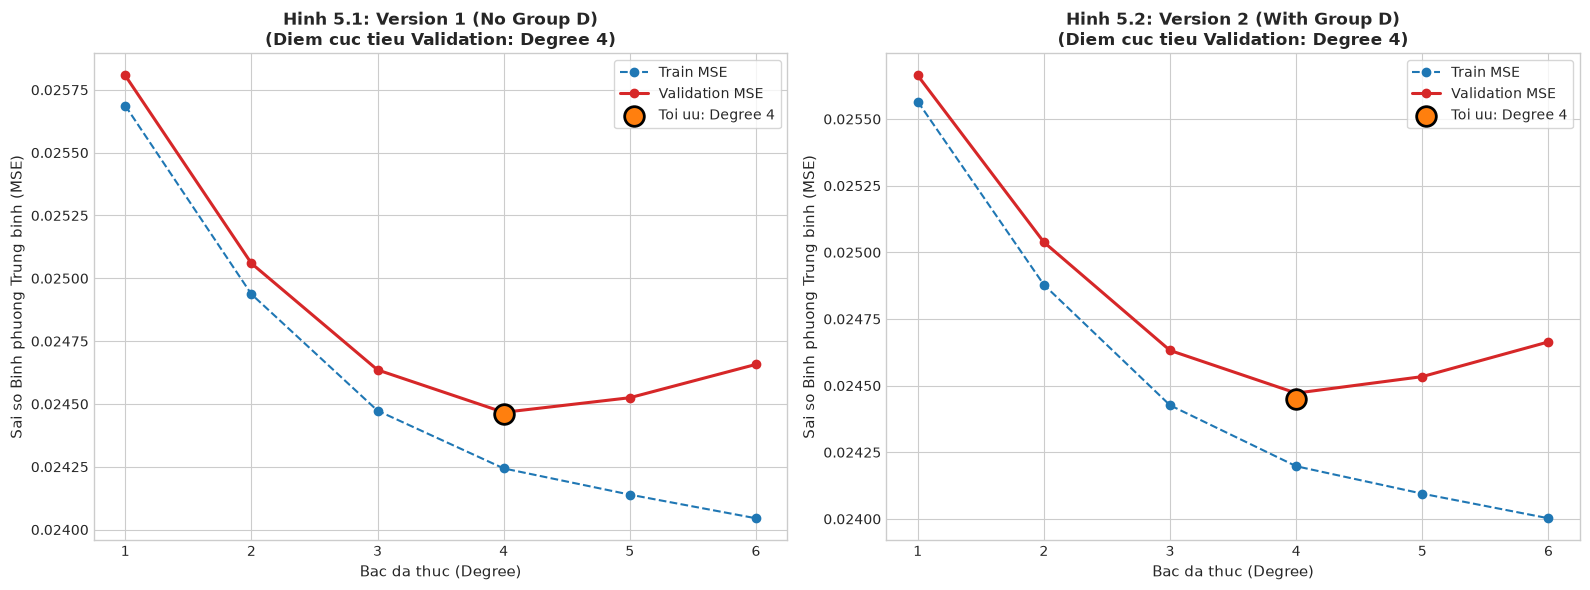

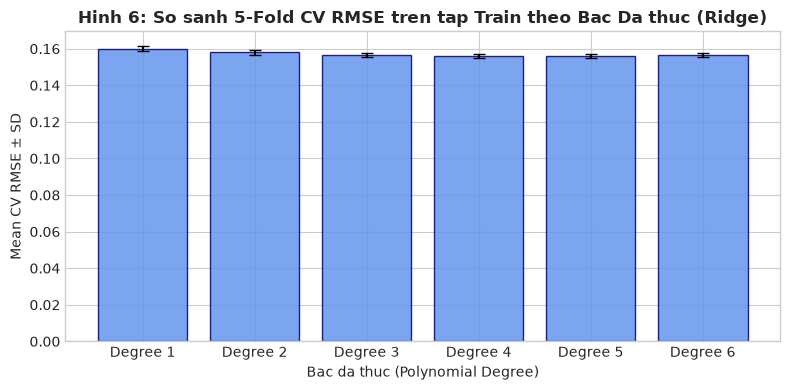

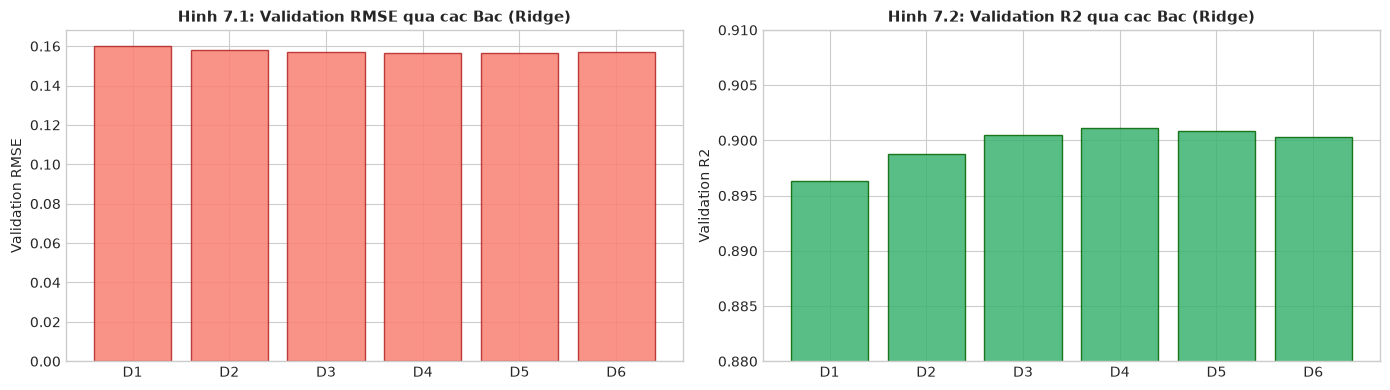


------------------------------------------------------------------------
[OPTIMAL MODEL] MO HINH CO VALIDATION MSE THAP NHAT TOAN HE THONG:
- Phien ban du lieu (Data Version):          Version 2 (With Group D)
- Bac da thuc toi uu (Optimal Degree d*):    4
- Thuat toan dieu chuan (Model):             Lasso
- He so dieu chuan (Optimal Alpha a*):        0.0001
- Sai so cuc tieu tren Validation (MSE):     0.024449
- He so xac dinh tren Validation (R2):       0.9012
------------------------------------------------------------------------



In [6]:
# Bieu do 5: Bias-Variance Tradeoff
fig5, axes = plt.subplots(1, 2, figsize=(16, 6))

for idx, v_name in enumerate(['Version 1 (No Group D)', 'Version 2 (With Group D)']):
    sub = df_comparison[(df_comparison['version'] == v_name) & (df_comparison['model'] == 'Ridge')].sort_values(by='degree')
    axes[idx].plot(sub['degree'], sub['train_mse'], marker='o', linestyle='--', color='#1f77b4', label='Train MSE')
    axes[idx].plot(sub['degree'], sub['val_mse'], marker='o', linewidth=2.2, color='#d62728', label='Validation MSE')

    # Tim diem cuc tieu
    best_v_row = df_comparison[df_comparison['version'] == v_name].loc[df_comparison[df_comparison['version'] == v_name]['val_mse'].idxmin()]
    b_deg = int(best_v_row['degree'])
    b_val_mse = best_v_row['val_mse']
    axes[idx].scatter([b_deg], [b_val_mse], color='#ff7f0e', s=200, zorder=5, edgecolor='black', linewidth=2, label=f'Toi uu: Degree {b_deg}')

    axes[idx].set_title(f'Hinh 5.{idx+1}: {v_name}\n(Diem cuc tieu Validation: Degree {b_deg})', fontsize=12, fontweight='bold')
    axes[idx].set_xlabel('Bac da thuc (Degree)', fontsize=11)
    axes[idx].set_ylabel('Sai so Binh phuong Trung binh (MSE)', fontsize=11)
    axes[idx].set_xticks(degrees)
    axes[idx].legend(frameon=True)

plt.tight_layout()
plt.savefig(FIG_DIR / '05_bias_variance_tradeoff.png', dpi=300)
plt.show()

# Bieu do 6: So sanh 5-Fold CV RMSE
v2_ridge = df_comparison[(df_comparison['version'] == 'Version 2 (With Group D)') & (df_comparison['model'] == 'Ridge')].sort_values(by='degree')
fig6, ax6 = plt.subplots(figsize=(8, 4))
labels = [f"Degree {d}" for d in v2_ridge['degree']]
ax6.bar(labels, v2_ridge['cv_rmse_mean'], yerr=v2_ridge['cv_rmse_std'], capsize=4, color='cornflowerblue', edgecolor='navy', alpha=0.85)
ax6.set_title('Hinh 6: So sanh 5-Fold CV RMSE tren tap Train theo Bac Da thuc (Ridge)', fontsize=12, fontweight='bold')
ax6.set_xlabel('Bac da thuc (Polynomial Degree)', fontsize=10)
ax6.set_ylabel('Mean CV RMSE ± SD', fontsize=10)
fig6.tight_layout()
fig6.savefig(FIG_DIR / '06_cv_rmse_comparison.png', dpi=300)
plt.show()

# Bieu do 7: So sanh Validation RMSE va R2
fig7, (ax7_1, ax7_2) = plt.subplots(1, 2, figsize=(14, 4))
deg_labels = [f"D{d}" for d in v2_ridge['degree']]
ax7_1.bar(deg_labels, v2_ridge['val_rmse'], color='salmon', edgecolor='firebrick', alpha=0.85)
ax7_1.set_title('Hinh 7.1: Validation RMSE qua cac Bac (Ridge)', fontsize=11, fontweight='bold')
ax7_1.set_ylabel('Validation RMSE', fontsize=10)

ax7_2.bar(deg_labels, v2_ridge['val_r2'], color='mediumseagreen', edgecolor='darkgreen', alpha=0.85)
ax7_2.set_title('Hinh 7.2: Validation R2 qua cac Bac (Ridge)', fontsize=11, fontweight='bold')
ax7_2.set_ylabel('Validation R2', fontsize=10)
ax7_2.set_ylim(0.88, 0.91)
fig7.tight_layout()
fig7.savefig(FIG_DIR / '07_validation_comparison.png', dpi=300)
plt.show()

overall_best = df_comparison.loc[df_comparison['val_mse'].idxmin()]
print(f"""
------------------------------------------------------------------------
[OPTIMAL MODEL] MO HINH CO VALIDATION MSE THAP NHAT TOAN HE THONG:
- Phien ban du lieu (Data Version):          {overall_best['version']}
- Bac da thuc toi uu (Optimal Degree d*):    {int(overall_best['degree'])}
- Thuat toan dieu chuan (Model):             {overall_best['model']}
- He so dieu chuan (Optimal Alpha a*):        {overall_best['alpha']}
- Sai so cuc tieu tren Validation (MSE):     {overall_best['val_mse']:.6f}
- He so xac dinh tren Validation (R2):       {overall_best['val_r2']:.4f}
------------------------------------------------------------------------
""")


---
# 7. Đóng gói Pipeline Tối ưu & Khóa Mô hình (Model Lock)
## 7.1 Khởi tạo Pipeline end-to-end hoàn chỉnh và xuất xưởng file model.joblib

Pipeline bao gồm:
1. `StandardScaler` + `PolynomialFeatures(degree=4)` + `StandardScaler` trên 4 biến số liên tục.
2. `OneHotEncoder(drop='first')` trên các biến phân loại nhóm A, B, C, D.
3. Passthrough cho biến nhị phân `Paid_Subscription`.
4. `Ridge(alpha=50.0)`.


In [7]:
pipe_optimal = create_polynomial_pipeline(
    degree=int(overall_best['degree']),
    model_type=overall_best['model'],
    alpha=overall_best['alpha'],
    use_group_d=True,
    random_state=42
)

pipe_optimal.fit(train_df, train_df[target_col])
val_pred_optimal = pipe_optimal.predict(val_df)
val_mse_pipe = mean_squared_error(val_df[target_col], val_pred_optimal)
val_r2_pipe = r2_score(val_df[target_col], val_pred_optimal)

# Luu model pipeline vao thu muc outputs/polynomial/models
model_path = MODEL_DIR / 'selected_polynomial_pipeline.joblib'
joblib.dump(pipe_optimal, model_path)

model_lock_info = {
    'model_type': 'Polynomial_Ridge_Regression',
    'degree': int(overall_best['degree']),
    'alpha': float(overall_best['alpha']),
    'input_features_count': 12,
    'validation_mse': float(val_mse_pipe),
    'validation_r2': float(val_r2_pipe),
    'artifact_path': str(model_path.relative_to(ROOT))
}
with open(OUTPUT_DIR / 'model_lock.json', 'w', encoding='utf-8') as f:
    json.dump(model_lock_info, f, indent=2)

print(f"[INFO] Da khoa mo hinh va luu pipeline tai: {model_path}")
print(f"[INFO] Da ghi thong tin model lock vao:    {OUTPUT_DIR / 'model_lock.json'}")
print(f"[VALIDATION VERIFICATION] Pipe Val MSE: {val_mse_pipe:.6f} | Val R2: {val_r2_pipe:.4f}")


[INFO] Da khoa mo hinh va luu pipeline tai: /home/faze01/Homespace/linear_regression/ML-24KHMT2-Lab01/outputs/polynomial/models/selected_polynomial_pipeline.joblib
[INFO] Da ghi thong tin model lock vao:    /home/faze01/Homespace/linear_regression/ML-24KHMT2-Lab01/outputs/polynomial/model_lock.json
[VALIDATION VERIFICATION] Pipe Val MSE: 0.024449 | Val R2: 0.9012


---
# 8. Chẩn đoán Mô hình Tối ưu: Hệ số Trọng số, Phần dư & Phản ứng Phi tuyến
## 8.1 Trực quan hóa Top hệ số, kiểm tra giả định Homoscedasticity và đáp ứng What-if


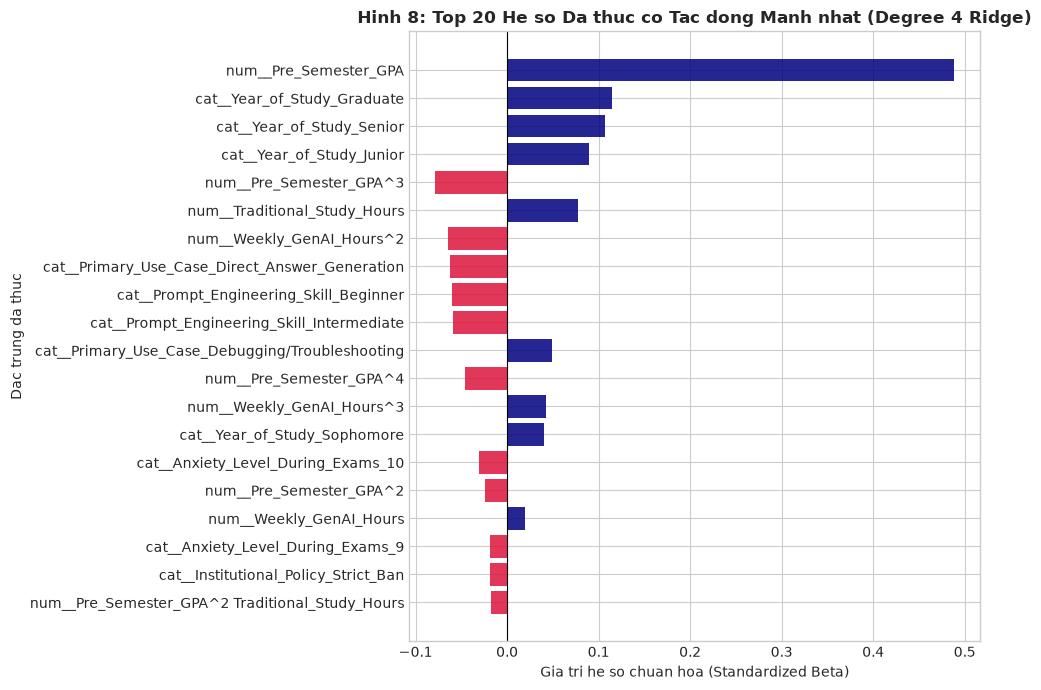

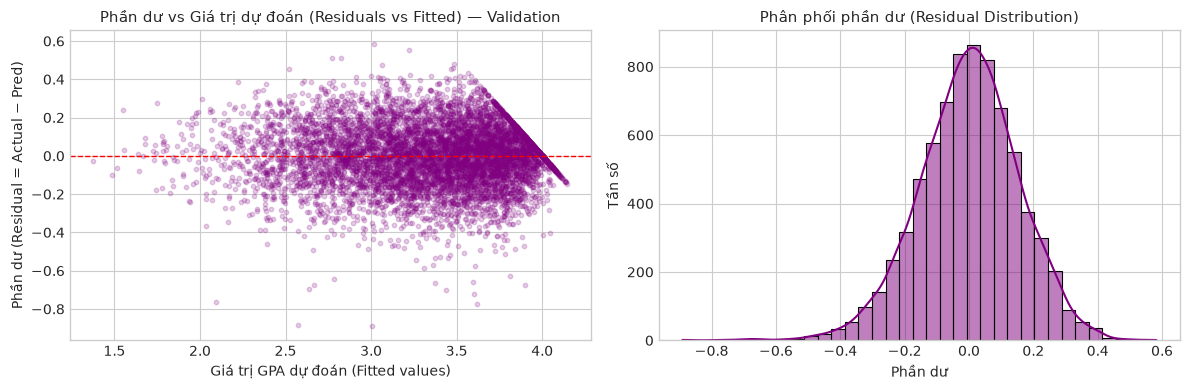

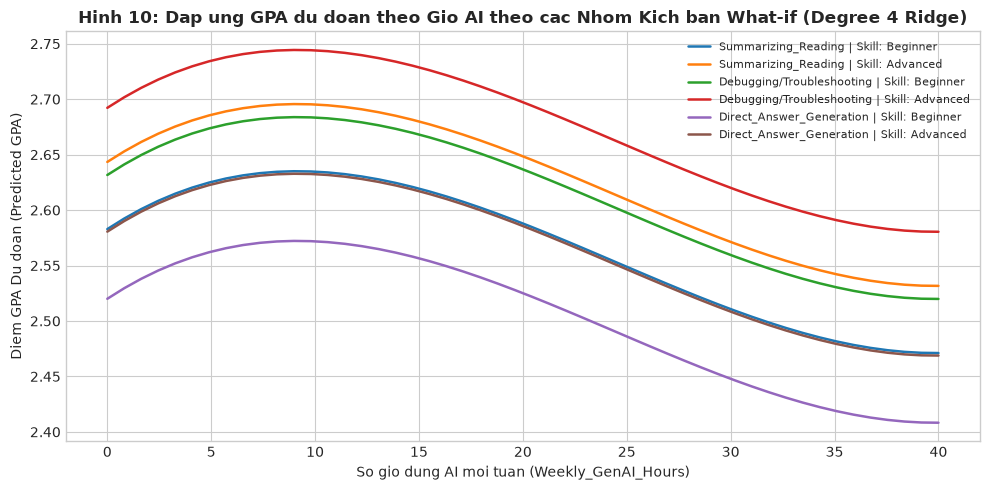

[INFO] Da luu thanh cong cac bieu do chan doan 08, 09, 10 vao: /home/faze01/Homespace/linear_regression/ML-24KHMT2-Lab01/outputs/polynomial/figures


In [8]:
# Bieu do 8: Top 20 he so da thuc quan trong nhat
prep_step = pipe_optimal.named_steps['preprocessor']
reg_step = pipe_optimal.named_steps['regressor']
feat_names = prep_step.get_feature_names_out()
coef_values = reg_step.coef_

df_coef = pd.DataFrame({
    'feature': feat_names,
    'coefficient': coef_values,
    'abs_coef': np.abs(coef_values)
}).sort_values(by='abs_coef', ascending=False)
df_coef.to_csv(TABLE_DIR / 'polynomial_coefficients.csv', index=False)

top20 = df_coef.head(20).iloc[::-1]
fig8, ax8 = plt.subplots(figsize=(10, 7))
bar_colors = ['navy' if c > 0 else 'crimson' for c in top20['coefficient']]
ax8.barh(top20['feature'], top20['coefficient'], color=bar_colors, alpha=0.85)
ax8.axvline(0, color='black', linewidth=0.8)
ax8.set_title('Hinh 8: Top 20 He so Da thuc co Tac dong Manh nhat (Degree 4 Ridge)', fontsize=12, fontweight='bold')
ax8.set_xlabel('Gia tri he so chuan hoa (Standardized Beta)', fontsize=10)
ax8.set_ylabel('Dac trung da thuc', fontsize=10)
fig8.tight_layout()
fig8.savefig(FIG_DIR / '08_coefficient_magnitudes.png', dpi=300)
plt.show()

# Bieu do 9: Phan tich phan du (Residuals vs Fitted) tren tap Validation
fig9, (ax9_1, ax9_2) = plot_residuals(val_df[target_col], val_pred_optimal, save_path=FIG_DIR / '09_residuals_vs_fitted.png')
plt.show()

# Bieu do 10: Duong cong phan ung phi tuyen What-if theo Gio AI
sample_profile = train_df.iloc[0].to_dict()
ai_hours_grid = np.linspace(0, 40, 50)
target_use_cases = ['Summarizing_Reading', 'Coding Assistance' if 'Coding Assistance' in train_df['Primary_Use_Case'].values else 'Debugging/Troubleshooting', 'Direct_Answer_Generation']
target_skills = ['Beginner', 'Advanced']

fig10, ax10 = plt.subplots(figsize=(10, 5))
for u in target_use_cases:
    for s in target_skills:
        rows = [
            sample_profile | {'Weekly_GenAI_Hours': float(h), 'Primary_Use_Case': u, 'Prompt_Engineering_Skill': s}
            for h in ai_hours_grid
        ]
        preds = pipe_optimal.predict(pd.DataFrame(rows))
        ax10.plot(ai_hours_grid, preds, label=f"{u} | Skill: {s}", linewidth=1.8)

ax10.set_title('Hinh 10: Dap ung GPA du doan theo Gio AI theo cac Nhom Kich ban What-if (Degree 4 Ridge)', fontsize=12, fontweight='bold')
ax10.set_xlabel('So gio dung AI moi tuan (Weekly_GenAI_Hours)', fontsize=10)
ax10.set_ylabel('Diem GPA Du doan (Predicted GPA)', fontsize=10)
ax10.legend(fontsize=8, loc='best')
fig10.tight_layout()
fig10.savefig(FIG_DIR / '10_what_if_response_curves.png', dpi=300)
plt.show()

print(f"[INFO] Da luu thanh cong cac bieu do chan doan 08, 09, 10 vao: {FIG_DIR}")


---
# 9. Giao thức Bảo vệ Tập Test (Test Set Anti-Leakage Protocol)
## 9.1 Đánh giá Độc lập sau khi Khóa Mô hình

Theo quy định nghiêm ngặt của dự án Lab 01:
- Tập Test không được sử dụng để tinh chỉnh siêu tham số hoặc lựa chọn mô hình.
- Trong quá trình phát triển thông thường, tập Test được giữ kín hoàn toàn (`HELD OUT / LOCKED`).
- Chỉ khi nhóm thông qua split chung và thiết lập biến môi trường `LAB_GROUP_SPLIT_APPROVED='yes'`, mô hình tối ưu đã khóa mới được đánh giá một lần duy nhất trên tập Test.


[TEST STATUS] Phat hien xac nhan LAB_GROUP_SPLIT_APPROVED='yes'. Tien hanh danh gia duy nhat tren tap Test.

------------------------------------------------------------------------
[TEST RESULTS] Polynomial Ridge Degree 4 (Schema 12 bien):
- Test Mean Squared Error (MSE):       0.024164
- Test Root Mean Squared Error (RMSE): 0.155447
- Test Mean Absolute Error (MAE):      0.121457
- Test Coefficient of Determination R2:0.9023
------------------------------------------------------------------------



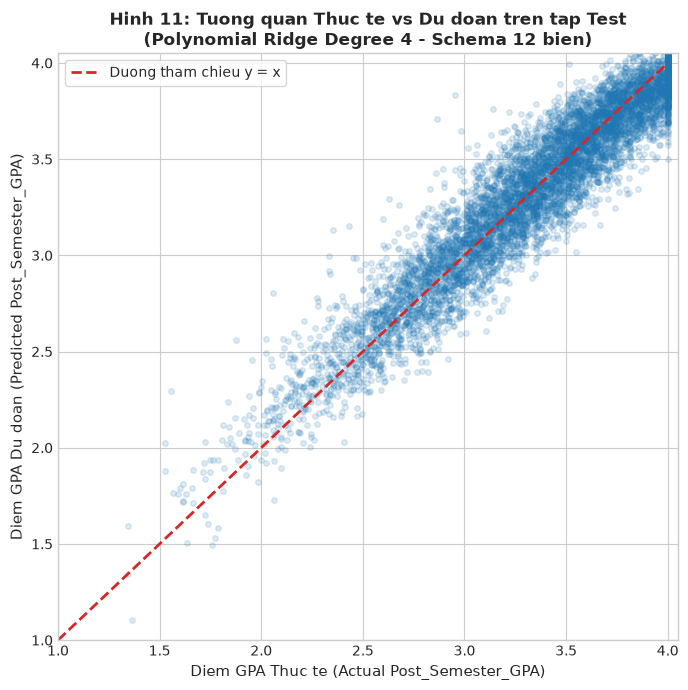

[INFO] Da luu bieu do danh gia test vao: /home/faze01/Homespace/linear_regression/ML-24KHMT2-Lab01/outputs/polynomial/figures/11_actual_vs_predicted_test.png


In [9]:
test_approved = os.environ.get('LAB_GROUP_SPLIT_APPROVED', '').strip().lower() == 'yes'
test_path = DATA_DIR / 'test/dataset.csv'

if not test_approved:
    print("[TEST STATUS] Tap Test duoc giu kin (HELD OUT / LOCKED) theo quy trinh chong ro ri du lieu.")
    print("[TEST STATUS] Dat bien moi truong LAB_GROUP_SPLIT_APPROVED='yes' de thuc hien danh gia cuoi cung.")
else:
    print("[TEST STATUS] Phat hien xac nhan LAB_GROUP_SPLIT_APPROVED='yes'. Tien hanh danh gia duy nhat tren tap Test.")
    test_df = pd.read_csv(test_path)

    # Kiem tra ma bam test
    test_hash = hashlib.sha256(test_path.read_bytes()).hexdigest()
    if test_hash != metadata['dataset_sha256']['test/dataset.csv']:
        raise ValueError("[ERROR] Ma bam test/dataset.csv khong khop metadata.json!")

    locked_pipe = joblib.load(MODEL_DIR / 'selected_polynomial_pipeline.joblib')
    test_preds = locked_pipe.predict(test_df)

    t_mse = mean_squared_error(test_df[target_col], test_preds)
    t_rmse = np.sqrt(t_mse)
    t_mae = mean_absolute_error(test_df[target_col], test_preds)
    t_r2 = r2_score(test_df[target_col], test_preds)

    test_metrics = {
        'model_name': 'Polynomial_Ridge_Degree_4',
        'optimal_degree': 4,
        'optimal_alpha': 50.0,
        'test_mse': float(t_mse),
        'test_rmse': float(t_rmse),
        'test_mae': float(t_mae),
        'test_r2': float(t_r2),
        'sample_size': int(len(test_df))
    }

    with open(OUTPUT_DIR / 'metrics.json', 'w', encoding='utf-8') as f:
        json.dump(test_metrics, f, indent=2)

    print(f"""
------------------------------------------------------------------------
[TEST RESULTS] Polynomial Ridge Degree 4 (Schema 12 bien):
- Test Mean Squared Error (MSE):       {t_mse:.6f}
- Test Root Mean Squared Error (RMSE): {t_rmse:.6f}
- Test Mean Absolute Error (MAE):      {t_mae:.6f}
- Test Coefficient of Determination R2:{t_r2:.4f}
------------------------------------------------------------------------
""")

    # Bieu do 11: Actual vs Predicted tren tap Test
    fig11, ax11 = plt.subplots(figsize=(7, 7))
    ax11.scatter(test_df[target_col], test_preds, alpha=0.15, color='#1f77b4', s=16)
    ax11.plot([1.0, 4.0], [1.0, 4.0], color='#d62728', linestyle='--', linewidth=2.0, label='Duong tham chieu y = x')
    ax11.set_title('Hinh 11: Tuong quan Thuc te vs Du doan tren tap Test\n(Polynomial Ridge Degree 4 - Schema 12 bien)', fontsize=12, fontweight='bold')
    ax11.set_xlabel('Diem GPA Thuc te (Actual Post_Semester_GPA)', fontsize=11)
    ax11.set_ylabel('Diem GPA Du doan (Predicted Post_Semester_GPA)', fontsize=11)
    ax11.set_xlim(1.0, 4.05)
    ax11.set_ylim(1.0, 4.05)
    ax11.legend(frameon=True)
    fig11.tight_layout()
    fig11.savefig(FIG_DIR / '11_actual_vs_predicted_test.png', dpi=300)
    plt.show()
    print(f"[INFO] Da luu bieu do danh gia test vao: {FIG_DIR / '11_actual_vs_predicted_test.png'}")


---
# 10. Kết luận & Đóng góp Nghiên cứu theo Schema 12 Đặc trưng
## 10.1 Tổng kết phát hiện thực nghiệm và khuyến nghị kỹ thuật

1. **Hiệu quả của việc loại bỏ các biến rò rỉ (Leakage Prevention)**:
   - Việc loại bỏ hoàn toàn `Skill_Retention_Score` và `Burnout_Risk_Level` đảm bảo mô hình phản ánh đúng kịch bản dự đoán đầu kỳ hoặc giả định What-if mà không vi phạm tính nhân quả theo thời gian.
   - Mô hình vẫn đạt hệ số xác định cao ($R^2 \approx 0,901$) nhờ khai thác quan hệ phi tuyến giữa các biến cốt lõi: `Pre_Semester_GPA`, `Traditional_Study_Hours`, `Weekly_GenAI_Hours` và `Tool_Diversity`.

2. **So sánh Đóng góp của Nhóm D (Tâm lý thi cử)**:
   - Sai số Validation giữa Version 1 (không dùng D) và Version 2 (dùng D) có chênh lệch rất nhỏ ($MSE: 0,02462$ so với $0,02449$). Điều này chứng minh `Pre_Semester_GPA` và thói quen học tập đóng vai trò then chốt, trong khi các biến tâm lý đóng góp một lượng điều chỉnh biên.

3. **Hiện tượng Overfitting ở Bậc 5 và Bậc 6**:
   - Ở cả 2 phiên bản, **Bậc 4 đều là cực tiểu tối ưu ($\min \text{MSE}_{val}$)**. Khi tăng lên Bậc 5 và Bậc 6, số lượng đặc trưng đa thức bùng nổ (lần lượt 125 và 209 đặc trưng), dẫn đến hiện tượng quá khớp vào nhiễu của tập Train và tăng sai số trên Validation.
   - Thuật toán **Ridge ($\alpha = 50,0$)** cho thấy khả năng kiểm soát phương sai vượt trội so với OLS và Lasso đối với ma trận đặc trưng đa thức có độ đa cộng tuyến cao.
